# Water bridges comparative analysis

In [1]:
import pandas as pd
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load data

In [ ]:
wt_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/waterbridges.csv')
    wt_dfs.append(wb_df)

T419R_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002.hbonds/waterbridges.csv')
    T419R_dfs.append(wb_df)

In [3]:
len(wt_dfs)

3

In [4]:
len(T419R_dfs)

3

In [14]:
print(wt_dfs[0].shape, wt_dfs[1].shape, wt_dfs[2].shape)

(1459, 11) (518, 11) (2557, 11)


In [15]:
print(T419R_dfs[0].shape, T419R_dfs[1].shape, T419R_dfs[2].shape)

(2349, 11) (1306, 11) (743, 11)


The number of identified water bridges (rows) varies greatly within replicates.

In [12]:
wt_dfs[1].head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle
0,100900.0,14154,417321,ARG,283,HH21,WAT,99835,H2,2.407864,120.306876
1,100900.0,417321,19732,WAT,99835,H2,DA,6,H2,2.974124,139.508148
2,101200.0,14155,152887,ARG,283,HH22,WAT,33727,O,3.146806,148.007760
3,101200.0,152889,19732,WAT,33727,H2,DA,6,H2,3.218076,123.058982
4,102000.0,14148,347531,ARG,283,HE,WAT,82388,O,2.109737,149.223424


## Filter direct hydrogen bonds and aggregate data

The identified "water bridges" include bonds that are in fact direct hydrogen bonds between the protein and DNA. We will filter these out to focus on water bridges.

In [46]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    combined= combined[(combined["sele1_resnm"] == "WAT") | (combined["sele2_resnm"] == "WAT")]
    agg_df = combined.groupby(['sele1_index', 'sele2_index', 'sele1_resid', 
                               'sele2_resid', 'sele1_resnm', 'sele2_resnm']).size().reset_index(name='count')

    agg_df['group'] = label
    return combined, agg_df

In [47]:

wt_combined, wt_agg = aggregate_hbonds(wt_dfs, 'wt')
mut_combined, mut_agg = aggregate_hbonds(T419R_dfs, 'T419R')

In [48]:
wt_agg.sort_values("count", ascending=False).head()

,sele1_index,sele2_index,sele1_resid,sele2_resid,sele1_resnm,sele2_resnm,count,group
185,4784,159880,286,35475,GLU,WAT,48,wt
353,14151,272345,283,63591,ARG,WAT,48,wt
352,14151,272343,283,63591,ARG,WAT,48,wt
261,4785,212660,286,48670,GLU,WAT,47,wt
110,4774,66375,286,12099,GLU,WAT,45,wt


In [59]:
wt_agg[wt_agg["sele1_resnm"] != "WAT"]["sele1_resid"].unique()

array([276, 278, 285, 286, 282, 283])

## Water bridges per frame

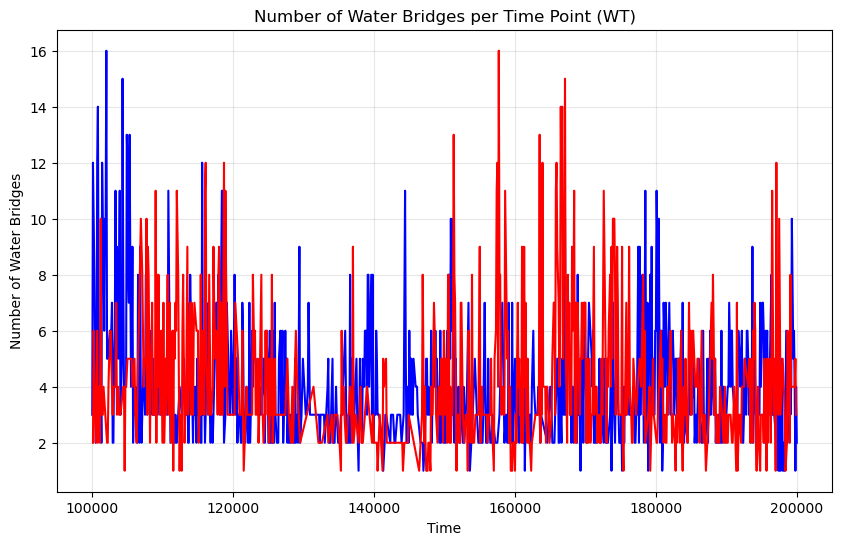

In [50]:
# Count rows per unique time value
time_counts_wt = wt_combined['time'].value_counts().sort_index()
time_counts_mut = mut_combined['time'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.plot(time_counts_wt.index, time_counts_wt.values, color='blue')
plt.plot(time_counts_mut.index, time_counts_mut.values, color='red')
plt.xlabel('Time')
plt.ylabel('Number of Water Bridges')
plt.title('Number of Water Bridges per Time Point (WT)')
plt.grid(True, alpha=0.3)
plt.show()

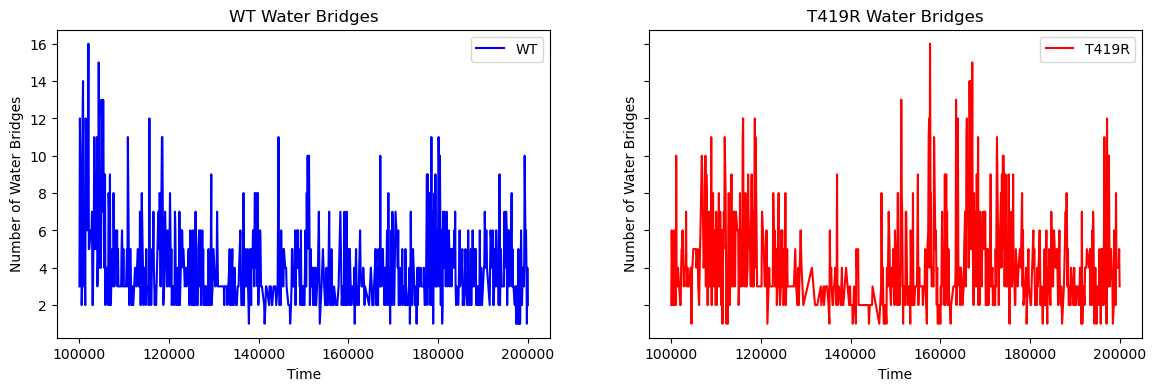

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax1, ax2 = axes.flatten()

ax1.plot(time_counts_wt.index, time_counts_wt.values, color='blue', label='WT')
ax2.plot(time_counts_mut.index, time_counts_mut.values, color='red', label='T419R')
ax1.set_xlabel('Time')
ax2.set_xlabel('Time')
ax1.set_ylabel('Number of Water Bridges')
ax2.set_ylabel('Number of Water Bridges')
ax1.set_title('WT Water Bridges')
ax2.set_title('T419R Water Bridges')
ax1.legend()
ax2.legend()

plt.show()

## Water bridges per residue

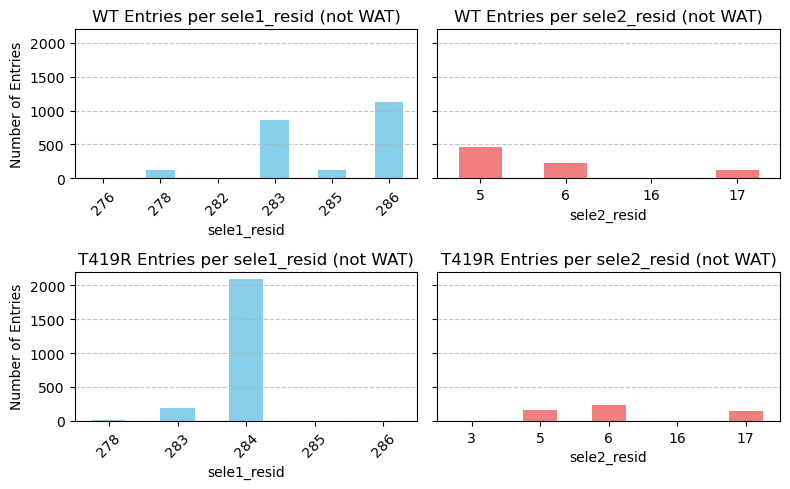

In [ ]:
sele1_filtered = wt_combined[wt_combined["sele1_resnm"] != "WAT"]
sele2_filtered = wt_combined[wt_combined["sele2_resnm"] != "WAT"]

# Count entries per resid
sele1_counts = sele1_filtered["sele1_resid"].value_counts().sort_index()
sele2_counts = sele2_filtered["sele2_resid"].value_counts().sort_index()

# Create side-by-side subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Plot sele1_resid
sele1_counts.plot(kind="bar", color="skyblue", ax=ax1)
ax1.set_xlabel("sele1_resid")
ax1.set_ylabel("Number of Entries")
ax1.set_title("WT Entries per sele1_resid (not WAT)")
ax1.grid(axis="y", linestyle="--", alpha=0.7)
ax1.tick_params(axis="x", rotation=45)

# Plot sele2_resid
sele2_counts.plot(kind="bar", color="lightcoral", ax=ax2)
ax2.set_xlabel("sele2_resid")
ax2.set_title("WT Entries per sele2_resid (not WAT)")
ax2.grid(axis="y", linestyle="--", alpha=0.7)
ax2.tick_params(axis="x", rotation=0)

combined_T419R = pd.concat(T419R_dfs)
# Filter for < 1000
sele1_filtered = mut_combined[mut_combined["sele1_resnm"] != "WAT"]
sele2_filtered = mut_combined[mut_combined["sele2_resnm"] != "WAT"]

# Count entries per resid
sele1_counts = sele1_filtered["sele1_resid"].value_counts().sort_index()
sele2_counts = sele2_filtered["sele2_resid"].value_counts().sort_index()

# Plot sele1_resid
sele1_counts.plot(kind="bar", color="skyblue", ax=ax3)
ax3.set_xlabel("sele1_resid")
ax3.set_ylabel("Number of Entries")
ax3.set_title("T419R Entries per sele1_resid (not WAT)")
ax3.grid(axis="y", linestyle="--", alpha=0.7)
ax3.tick_params(axis="x", rotation=45)

# Plot sele2_resid
sele2_counts.plot(kind="bar", color="lightcoral", ax=ax4)
ax4.set_xlabel("sele2_resid")
ax4.set_title("T419R Entries per sele2_resid (not WAT)")
ax4.grid(axis="y", linestyle="--", alpha=0.7)
ax4.tick_params(axis="x", rotation=0)

# Adjust layout
plt.tight_layout()
plt.show()

### Mapping protein-water-DNA triplets
#### WT

In [64]:
wt_combined["water_resid"] = np.where(wt_combined["sele1_resnm"] == "WAT", wt_combined["sele1_resid"], wt_combined["sele2_resid"])
wt_combined["water_sele"] = np.where(wt_combined["sele1_resnm"] == "WAT", 1, 2)

In [65]:
wt_combined.head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,water_resid,water_sele
2,100100.0,14152,26681,ARG,283,HH12,WAT,2175,H2,2.252311,145.427315,2175,2
3,100100.0,26681,19732,WAT,2175,H2,DA,6,H2,3.348624,140.971528,2175,1
4,100100.0,14152,26679,ARG,283,HH12,WAT,2175,O,1.878968,157.572021,2175,2
5,100100.0,14155,26681,ARG,283,HH22,WAT,2175,H2,2.634940,131.589160,2175,2
6,100100.0,14155,26679,ARG,283,HH22,WAT,2175,O,3.060673,121.029822,2175,2


In [124]:
def wb_triplets(combined_df):
    amino_acids = ["ARG", "LYS", "HIS", "SER", "THR", "ASN", "GLN", "ASP", "GLU", "ALA", "GLY", "PRO", "VAL", "LEU", "ILE", "MET", "PHE", "TYR", "TRP", "CYS"]
    bases = ["DA", "DT", "DG", "DC"]

    bridges = []
    for (time, water_resid), group in combined_df.groupby(["time", "water_resid"]):

        aa_to_water_rows = []
        water_to_base_rows = []
        
        # Loop over unique water_sele values in the group
        for water_sele in group["water_sele"].unique():
            # Filter group for this water_sele
            sele_group = group[group["water_sele"] == water_sele]
            
            # Check for amino acid-to-water and water-to-base pairs
            if water_sele == 1:
                aa_to_water = sele_group[(sele_group["sele2_resnm"].isin(amino_acids)) & (sele_group["sele1_resnm"] == "WAT")]
                water_to_base = sele_group[(sele_group["sele1_resnm"] == "WAT") & (sele_group["sele2_resnm"].isin(bases))]
            else:  # water_sele == 2 or other values
                aa_to_water = sele_group[(sele_group["sele1_resnm"].isin(amino_acids)) & (sele_group["sele2_resnm"] == "WAT")]
                water_to_base = sele_group[(sele_group["sele2_resnm"] == "WAT") & (sele_group["sele1_resnm"].isin(bases))]
            
            # Collect rows
            if not aa_to_water.empty:
                aa_to_water_rows.append(aa_to_water)
            if not water_to_base.empty:
                water_to_base_rows.append(water_to_base)
        
        # Combine rows into single DataFrames
        aa_to_water = pd.concat(aa_to_water_rows) if aa_to_water_rows else pd.DataFrame()
        water_to_base = pd.concat(water_to_base_rows) if water_to_base_rows else pd.DataFrame()

        if not aa_to_water.empty and not water_to_base.empty:
            for _, row1 in aa_to_water.iterrows():
                if water_sele == 1:
                    aa_resnm = row1["sele1_resnm"]
                    aa_resid = row1["sele1_resid"]
                else:
                    aa_resnm = row1["sele2_resnm"]
                    aa_resid = row1["sele2_resid"]
                for _, row2 in water_to_base.iterrows():
                    if water_sele == 1:
                        nt_resnm = row2["sele2_resnm"]
                        nt_resid = row2["sele2_resid"]
                    else:
                        nt_resnm = row2["sele1_resnm"]
                        nt_resid = row2["sele1_resid"]
                    bridges.append({
                        "time": time,
                        "aa": f"{aa_resnm} {aa_resid}",
                        "nt": f"{nt_resnm} {nt_resid}",
                        "water_resid": water_resid,
                        "distance1": row1["distance"],
                        "angle1": row1["angle"],
                        "distance2": row2["distance"],
                        "angle2": row2["angle"]
                    })
    return pd.DataFrame(bridges)

In [125]:
wt_triplets = wb_triplets(wt_combined)

In [126]:
wt_triplets.shape

(1518, 8)

In [127]:
wt_triplets.head()

,time,aa,nt,water_resid,distance1,angle1,distance2,angle2
0,100000.0,ARG 283,DA 6,60584,2.912734,161.218169,2.686466,127.536285
1,100000.0,ARG 283,DA 6,60584,2.163450,157.187995,2.686466,127.536285
2,100100.0,ARG 283,DA 6,2175,2.252311,145.427315,3.348624,140.971528
3,100100.0,ARG 283,DA 6,2175,1.878968,157.572021,3.348624,140.971528
4,100100.0,ARG 283,DA 6,2175,2.634940,131.589160,3.348624,140.971528


In [128]:
wt_triplets_agg = wt_triplets.groupby(["aa", "nt"]).size().reset_index(name='count')

In [129]:
wt_triplets_agg.sort_values("count", ascending=False)

,aa,nt,count
5,GLU 286,DA 5,759
1,ARG 283,DA 6,448
7,LYS 278,DA 17,111
0,ARG 283,DA 17,109
2,ASN 285,DA 5,50
3,ASN 285,DA 6,27
8,THR 282,DA 6,6
4,GLU 276,DA 17,5
6,LYS 278,DA 16,3


#### T419R

In [130]:
mut_combined["water_resid"] = np.where(mut_combined["sele1_resnm"] == "WAT", mut_combined["sele1_resid"], mut_combined["sele2_resid"])
mut_combined["water_sele"] = np.where(mut_combined["sele1_resnm"] == "WAT", 1, 2)

In [131]:
mut_combined.head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,water_resid,water_sele
5,100500.0,14185,430513,ARG,284,HH11,WAT,103128,H2,2.305869,124.223508,103128,2
6,100500.0,14185,430511,ARG,284,HH11,WAT,103128,O,2.045366,141.165374,103128,2
8,100600.0,4672,335721,LYS,278,HZ2,WAT,79430,H2,3.480936,163.184935,79430,2
9,100600.0,4672,335719,LYS,278,HZ2,WAT,79430,O,2.747037,159.924938,79430,2
10,100700.0,14185,430513,ARG,284,HH11,WAT,103128,H2,2.158095,138.892803,103128,2


In [132]:
mut_triplets = wb_triplets(mut_combined)

In [133]:
mut_triplets.shape

(1099, 8)

In [134]:
mut_triplets_agg = mut_triplets.groupby(["aa", "nt"]).size().reset_index(name='count')

In [135]:
mut_triplets_agg.sort_values("count", ascending=False)

,aa,nt,count
6,ARG 284,DA 6,463
5,ARG 284,DA 5,301
3,ARG 284,DA 17,293
1,ARG 283,DA 17,24
8,LYS 278,DA 17,9
0,ARG 283,DA 16,4
4,ARG 284,DA 3,3
2,ARG 283,DA 5,1
7,ASN 285,DA 6,1


TODO adjust AA residue numbers!